# 02 — What Does the Baseline Model Rely On?

Inspect the baseline Random Forest using a stratified **80/20 train/validation split** of the training file. The official test set stays untouched for final evaluation (spec 8.1).

## 1. Setup & validation metrics

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

from cybershield.ml.preprocessing import TRAIN_CSV, load_csv, split_xy
from cybershield.ml.train import SEED, build_model, evaluate

COLOR = "#2a78d6"
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

X, y = split_xy(load_csv(TRAIN_CSV))
X_fit, X_val, y_fit, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

model = build_model().fit(X_fit, y_fit)
val = evaluate(y_val, model.predict(X_val))

metrics = pd.Series({
    "Precision": val["precision"],
    "Recall": val["recall"],
    "F1": val["f1"],
    "False-Positive Rate": val["false_positive_rate"],
}, name="Validation")
metrics.to_frame().style.format("{:.1%}")

,Validation
Precision,96.5%
Recall,97.7%
F1,97.1%
False-Positive Rate,7.6%


### Validation vs. official test
Validation FPR is **7.6%**, compared to **26.8%** on the official test set (~3.5× higher).

Why the gap? Validation rows come from the **same capture recordings** as the fit split (sharing duplicates and OS/TTL quirks). Test rows come from different traffic where those shortcuts fail. Always treat the test score as the honest benchmark.

## 2. Impurity importance (built-in)
Sums each feature's split-purity gain across all 100 trees (one-hot columns like `proto_*` are summed back into their original feature). Computed on training data and biased toward high-cardinality numeric features.

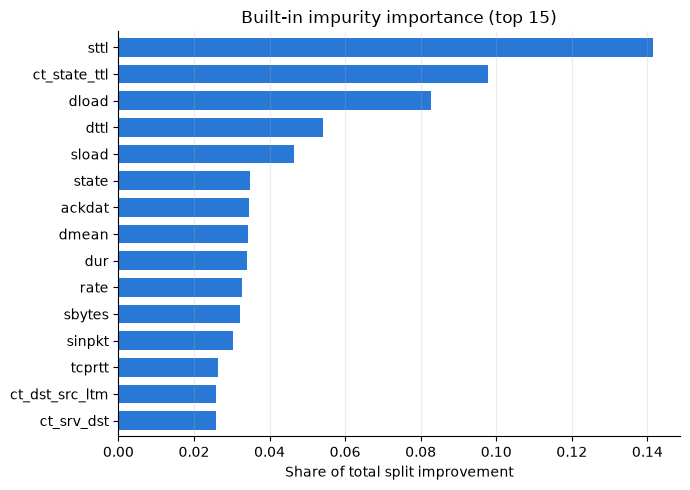

In [2]:
feature_names = model[:-1].get_feature_names_out()
raw_imp = pd.Series(model[-1].feature_importances_, index=feature_names)
original_col = raw_imp.index.str.replace(r"^(proto|service|state)_.*", r"\1", regex=True)
impurity = raw_imp.groupby(original_col).sum().sort_values()

fig, ax = plt.subplots(figsize=(7, 5))
impurity.tail(15).plot.barh(ax=ax, color=COLOR, width=0.7)
ax.set(title="Built-in impurity importance (top 15)", xlabel="Share of total split improvement")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 3. Permutation importance (validation)
Shuffles one column at a time on the held-out validation set and measures the drop in balanced accuracy. More trustworthy than impurity importance because it evaluates on unseen rows and original features directly.

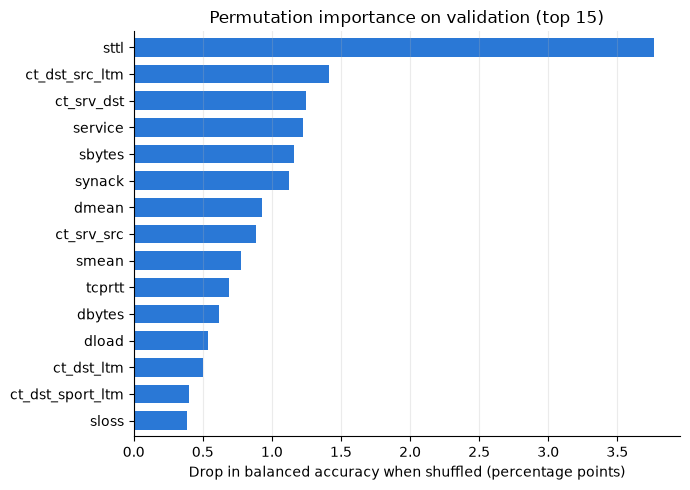

Features with near-zero impact (<0.05 pp): 9 of 42


In [3]:
perm_result = permutation_importance(
    model, X_val, y_val,
    scoring="balanced_accuracy",
    n_repeats=3,
    random_state=SEED,
    n_jobs=-1,
)
perm = pd.Series(perm_result.importances_mean, index=X_val.columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 5))
perm.tail(15).mul(100).plot.barh(ax=ax, color=COLOR, width=0.7)
ax.set(
    title="Permutation importance on validation (top 15)",
    xlabel="Drop in balanced accuracy when shuffled (percentage points)",
)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

zero_impact = (perm.abs() < 0.0005).sum()
print(f"Features with near-zero impact (<0.05 pp): {zero_impact} of {len(perm)}")

## Key takeaways
- **`sttl` dominates both methods**, confirming the model relies heavily on lab-specific TTL values.
- **9 of 42 features** have virtually no effect when shuffled.
- **Validation (7.6% FPR) vs. test (26.8% FPR)** shows that random splits from the same capture overestimate real-world generalization.